In [4]:
import pandas as pd
url = "https://raw.github.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"
df=pd.read_csv(url)
print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [5]:
print(df.info())
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [8]:
df['posted_at']=pd.to_datetime(df['posted_at'],format='%d-%m-%Y')

In [9]:
import numpy as np
import pandas as pd
likes_array = np.array(df['likes'])
print("mean likes:", np.mean(likes_array))
print("max likes:", np.max(likes_array))
print("min likes:", np.min(likes_array))
print("sum likes:", np.sum(likes_array))

mean likes: nan
max likes: nan
min likes: nan
sum likes: nan


In [11]:
import pandas as pd
print("---missing values check---")
print(df.isnull().sum())
print(df.isna().sum())

---missing values check---
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [12]:
df_no_missing = df.dropna()
print(f"\nafter dropna shape: {df_no_missing.shape}")


after dropna shape: (4162, 19)


In [18]:
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())


In [19]:
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst= True,errors='coerce')
df = df.sort_values('posted_at')
df['likes'] = df['likes'].ffill()
df['likes'] = df['likes'].bfill()

In [20]:
print(f"\nduplicate rows: {df.duplicated().sum()}")



duplicate rows: 0


In [21]:
df = df.drop_duplicates()
print(f"after removing duplicates shape: {df.shape}")


after removing duplicates shape: (5000, 19)


In [22]:
print("\nfinal cleaned data:")
print(df.info())


final cleaned data:
<class 'pandas.DataFrame'>
Index: 5000 entries, 3876 to 1917
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified     

In [23]:
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst=True,errors='coerce')
df['likes'] = pd.to_numeric(df['likes'],errors='coerce')
df['comments'] = pd.to_numeric(df['comments'],errors='coerce')
df['shares'] = pd.to_numeric(df['shares'],errors='coerce')
df['is_verified'] = df['is_verified'].astype(bool)
print("---after fixing datatypes---")
print(df.dtypes)

---after fixing datatypes---
user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object


In [24]:
df['sentiment'] = df['sentiment'].str.lower().str.strip()
df['device_type'] = df['device_type'].str.lower().str.strip()
print(df['sentiment'].value_counts())
print(df['device_type'].value_counts())

sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64


In [25]:
df['likes'] = df['likes'].clip(lower=0)
df['comments'] = df['comments'].clip(lower=0)
df['shares'] = df['shares'].clip(lower=0)
print(df[['likes','comments','shares']].describe())

              likes     comments     shares
count   5000.000000  5000.000000  5000.0000
mean   10106.997400  1502.039800  1002.9106
std     5702.293017   856.393312   570.8552
min       10.000000     0.000000     0.0000
25%     5235.000000   792.000000   511.0000
50%    10105.500000  1497.000000  1012.0000
75%    14959.000000  2235.250000  1483.0000
max    19998.000000  2999.000000  1999.0000


In [27]:
df['hashtag_count'] = df['post_type'].str.count('#')
print(df[['post_type','hashtag_count']].head())

     post_type  hashtag_count
3876     video              0
3944     video              0
2891     video              0
1044      reel              0
570       text              0


In [28]:
df['sentiment'] = df['sentiment'].astype(str).str.lower().str.strip()
print(df['sentiment'].value_counts())

sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64


In [29]:
print("head")
print(df.head())

head
      user_id   age  gender    country  post_id post_type post_category  \
3876    65745  20.0  Female        USA   716149     video     education   
3944    73232  58.0    Male     Brazil   763662     video     lifestyle   
2891    16629  50.0  Female     France   916929     video          tech   
1044    19446  54.0  Female      India   106028      reel       fashion   
570     97508  48.0    Male  Australia   155313      text     lifestyle   

        likes  comments  shares  watch_time_sec  impression_count  posted_at  \
3876   5780.0    1926.0  1536.0            4193             11037 2022-01-01   
3944  10924.0     992.0  1461.0            2174             11361 2022-01-01   
2891  19873.0     243.0  1918.0            6385              1334 2022-01-01   
1044   9723.0     248.0  1817.0            5305             92434 2022-01-01   
570    4000.0    2900.0   714.0            1490              8166 2022-01-01   

      follower_count  is_verified device_type sentiment        

In [30]:
print("tail")
print(df.tail())
      

tail
      user_id   age  gender    country  post_id post_type post_category  \
1473    43933  31.0    Male  Australia   247089     video       fitness   
2929    87275  27.0  Female    Germany   875299     image       fitness   
702     33793  44.0  Female    Germany   530898     video          food   
3151    52604  59.0  Female     Canada   608594     video          tech   
1917    86367  52.0   Other        UAE   601817      reel       fitness   

        likes  comments  shares  watch_time_sec  impression_count  posted_at  \
1473  15252.0     177.0   836.0            6567             59124 2023-12-31   
2929  12378.0    2613.0  1138.0            3161             99489 2023-12-31   
702     345.0    1164.0   334.0             472               328 2023-12-31   
3151   1049.0     751.0  1046.0            1616             65636 2023-12-31   
1917  10486.0     774.0   628.0            1886             88021 2023-12-31   

      follower_count  is_verified device_type sentiment  \
1473

In [32]:
print("columns")
print(df.columns.tolist())

columns
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [33]:
print("info")
print(df.info())

info
<class 'pandas.DataFrame'>
Index: 5000 entries, 3876 to 1917
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null 

In [34]:
print("dtypes")
print(df.dtypes)

dtypes
user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object


In [35]:
print("describe")
print(df.describe())

describe
            user_id          age        post_id         likes     comments  \
count   5000.000000  4850.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.454021  548042.909000  10106.997400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.912381  260646.957267   5702.293017   856.393312   

          shares  watch_time_sec  impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   
50%    1012.0000  

In [36]:
print("value_counts()")
print(df['sentiment'].value_counts())
print(df['device_type'].value_counts())

value_counts()
sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64


In [37]:
print("unique()")
print(df['sentiment'].unique())
print(df['device_type'].unique())

unique()
<StringArray>
['positive', 'negative', 'neutral', nan]
Length: 4, dtype: str
<StringArray>
['tablet', 'mobile', 'desktop']
Length: 3, dtype: str


In [38]:
print("nunique()")
print(df['sentiment'].nunique())
print(df['device_type'].nunique())

nunique()
3
3


In [39]:
print(df.corr(numeric_only=True))

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006789  0.020051  0.025811 -0.033395  0.013763   
age              -0.006789  1.000000 -0.013353 -0.036767 -0.007369  0.014120   
post_id           0.020051 -0.013353  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036767  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007369 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.014120  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005677  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013513 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.025416 -0.002844 -0.022982 -0.011733 -0.010783   
is_verified       0.004058 -0.000112  0.025208 -0.016200 -0.012398  0.007025   
engagement_rate  -0.004282  0.008044  0.010139  0.093520  0.000051  0.021724   
hashtag_count          NaN       NaN    

In [42]:
df.groupby('post_type')['likes'].mean()
df.groupby('country')['impression_count'].mean()

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64

In [44]:
df1 = df.head(100)
df2 = df.tail(100)
pd.concat([df1,df2])

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
3876,65745,20.0,Female,USA,716149,video,education,5780.0,1926.0,1536.0,4193,11037,2022-01-01,2342,False,tablet,positive,#fun,0.837365,0
3944,73232,58.0,Male,Brazil,763662,video,lifestyle,10924.0,992.0,1461.0,2174,11361,2022-01-01,712234,False,tablet,negative,#fun,1.177449,0
2891,16629,50.0,Female,France,916929,video,tech,19873.0,243.0,1918.0,6385,1334,2022-01-01,357021,False,mobile,neutral,#foodie #reels #love,16.517241,0
1044,19446,54.0,Female,India,106028,reel,fashion,9723.0,248.0,1817.0,5305,92434,2022-01-01,626156,False,tablet,positive,#music,0.127529,0
570,97508,48.0,Male,Australia,155313,text,lifestyle,4000.0,2900.0,714.0,1490,8166,2022-01-01,74642,False,mobile,negative,#fashion #travel,0.932403,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1473,43933,31.0,Male,Australia,247089,video,fitness,15252.0,177.0,836.0,6567,59124,2023-12-31,769998,False,desktop,positive,#love,0.275100,0
2929,87275,27.0,Female,Germany,875299,image,fitness,12378.0,2613.0,1138.0,3161,99489,2023-12-31,276458,True,desktop,positive,#music,0.162118,0
702,33793,44.0,Female,Germany,530898,video,food,345.0,1164.0,334.0,472,328,2023-12-31,667588,False,tablet,neutral,#fun,5.618902,0
3151,52604,59.0,Female,Canada,608594,video,tech,1049.0,751.0,1046.0,1616,65636,2023-12-31,749628,False,mobile,positive,#fun #fitness #reels,0.043360,0


In [49]:
df_merged =pd.merge(df1, df2, on='post_id' ,how='inner')
df_merged.head()

,user_id_x,age_x,gender_x,country_x,post_id,post_type_x,post_category_x,likes_x,comments_x,shares_x,...,watch_time_sec_y,impression_count_y,posted_at_y,follower_count_y,is_verified_y,device_type_y,sentiment_y,hashtags_y,engagement_rate_y,hashtag_count_y


In [52]:
df_join = df1.join(df2, how='left', lsuffix='_1', rsuffix='_2')
df_join.head()

C:\Users\hp\AppData\Local\Temp\ipykernel_6572\2896233829.py:1: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  df_join = df1.join(df2, how='left', lsuffix='_1', rsuffix='_2')


,user_id_1,age_1,gender_1,country_1,post_id_1,post_type_1,post_category_1,likes_1,comments_1,shares_1,...,watch_time_sec_2,impression_count_2,posted_at_2,follower_count_2,is_verified_2,device_type_2,sentiment_2,hashtags_2,engagement_rate_2,hashtag_count_2
3876,65745,20.0,Female,USA,716149,video,education,5780.0,1926.0,1536.0,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3944,73232,58.0,Male,Brazil,763662,video,lifestyle,10924.0,992.0,1461.0,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2891,16629,50.0,Female,France,916929,video,tech,19873.0,243.0,1918.0,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1044,19446,54.0,Female,India,106028,reel,fashion,9723.0,248.0,1817.0,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
570,97508,48.0,Male,Australia,155313,text,lifestyle,4000.0,2900.0,714.0,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [61]:
df['engagement_score'] = df['likes'] + df['comments']+ df['shares']
df['hastag_count'] = df['hashtags'].str.count('#')
df[['likes','comments','shares','engagement_score','hashtag_count']].head()
df['log_likes'] = np.log1p(df['likes'])
df['log_engagement'] = np.log1p(df['engagement_score'])
df[['likes','engagement_score','log_likes','log_engagement']].head()

,likes,engagement_score,log_likes,log_engagement
3876,5780.0,9242.0,8.662332,9.131622
3944,10924.0,13377.0,9.298809,9.501367
2891,19873.0,22034.0,9.897168,10.000387
1044,9723.0,11788.0,9.182352,9.374922
570,4000.0,7614.0,8.294300,8.937875


In [62]:
df.groupby ('post_type')['engagement_score'].agg(['mean','median','sum','count'])


,mean,median,sum,count
post_type,,,,
image,12649.390537,12881.5,15773790.0,1247
reel,12524.031567,12279.0,16068332.5,1283
text,12613.243775,12457.0,15703488.5,1245
video,12664.594286,12634.0,15514128.0,1225


In [63]:
df.groupby('country')['engagement_score'].agg(['mean','median','sum','count'])

,mean,median,sum,count
country,,,,
Australia,12809.621704,13030.00,6315143.5,493
Brazil,12385.983135,11879.25,6242535.5,504
Canada,12605.894737,12450.00,6466824.0,513
France,12903.384073,13314.00,6400078.5,496
Germany,12635.664286,12612.50,6191475.5,490
India,12492.701869,12543.50,6683595.5,535
Japan,12578.648305,12593.25,5937122.0,472
UAE,12757.777336,12987.50,6417162.0,503
UK,12384.374239,12107.00,6105496.5,493


In [64]:
df.groupby('sentiment')['engagement_score'].agg(['mean','median','sum','count'])

,mean,median,sum,count
sentiment,,,,
negative,12731.498958,12578.5,12222239.0,960
neutral,12448.163720,12244.0,19008346.0,1527
positive,12641.209056,12674.0,29871177.0,2363


In [71]:
cols = ['likes','comments','shares']
summary = pd.DataFrame()
summary['mean'] = df[cols].mean()
summary['median'] = df[cols].median()
summary['mode'] = df[cols].mode().iloc[0]
summary['std'] = df[cols].std()
summary['variance'] = df[cols].var()
summary['min'] = df[cols].min()
summary['max'] = df[cols].max()
summary

,mean,median,mode,std,variance,min,max
likes,10106.9974,10105.5,10105.5,5702.293017,3.251615e+07,10.0,19998.0
comments,1502.0398,1497.0,1497.0,856.393312,7.334095e+05,0.0,2999.0
shares,1002.9106,1012.0,1012.0,570.855200,3.258757e+05,0.0,1999.0


In [72]:
summary['25%'] = df[cols].quantile(0.25)
summary['75%'] = df[cols].quantile(0.75)
summary['90%'] = df[cols].quantile(0.90)
summary['skewness'] = df[cols].skew()
summary['kurtosis'] = df[cols].kurtosis()
summary

,mean,median,mode,std,variance,min,max,25%,75%,90%,skewness,kurtosis
likes,10106.9974,10105.5,10105.5,5702.293017,3.251615e+07,10.0,19998.0,5235.0,14959.00,18016.3,-0.006894,-1.149992
comments,1502.0398,1497.0,1497.0,856.393312,7.334095e+05,0.0,2999.0,792.0,2235.25,2695.1,0.003802,-1.144375
shares,1002.9106,1012.0,1012.0,570.855200,3.258757e+05,0.0,1999.0,511.0,1483.00,1795.1,-0.014654,-1.146857


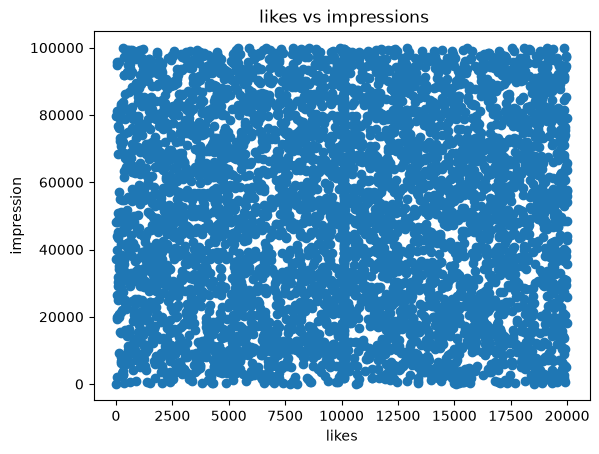

In [81]:
import matplotlib.pyplot as plt
plt.figure()
plt.scatter(df['likes'],df['impression_count'])
plt.xlabel('likes')
plt.ylabel('impression')
plt.title(' likes vs impressions')
plt.show()

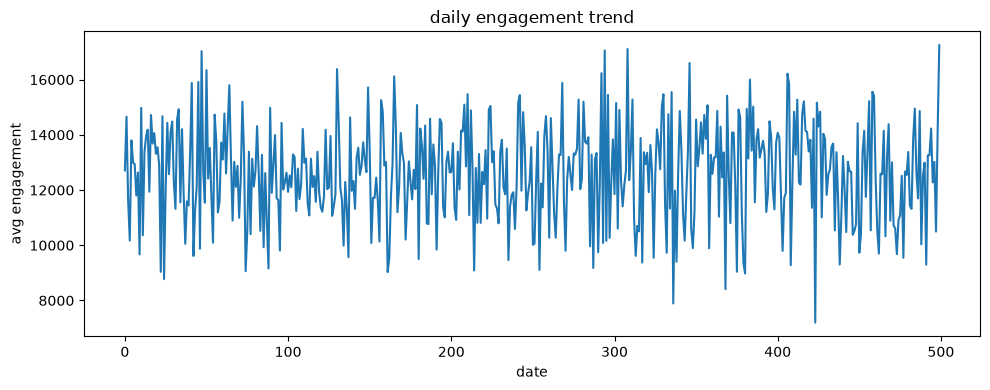

In [83]:
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    daily = df.groupby('date')['engagement_score'].mean()
else:
    daily = df.groupby(df.index// 10)['engagement_score'].mean()
plt.close('all')
plt.figure(figsize=(10,4))
plt.plot(daily.index,daily.values,)
plt.xlabel('date')
plt.ylabel('avg engagement')
plt.title('daily engagement trend')
plt.tight_layout()
plt.show()

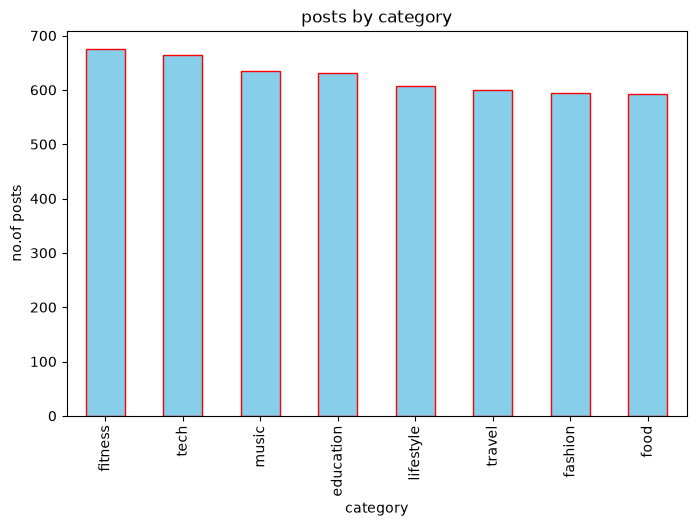

In [85]:
plt.figure(figsize=(8,5))
df['post_category'].value_counts().plot(kind='bar',color='skyblue',edgecolor='red')
plt.xlabel('category')
plt.ylabel('no.of posts')
plt.title('posts by category')
plt.show()

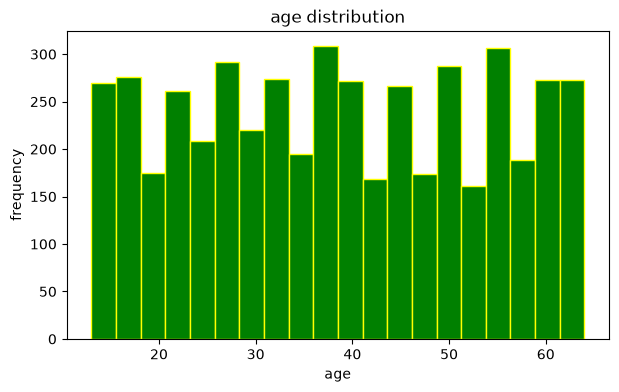

In [87]:
plt.figure(figsize=(7,4))
plt.hist(df['age'], bins=20,color='green',edgecolor='yellow')
plt.xlabel('age')
plt.ylabel('frequency')
plt.title('age distribution')
plt.show()
           
          

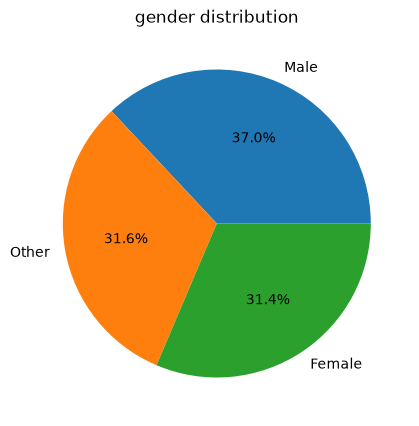

In [88]:
plt.figure(figsize=(5,5))
df['gender'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.title('gender distribution')
plt.show()


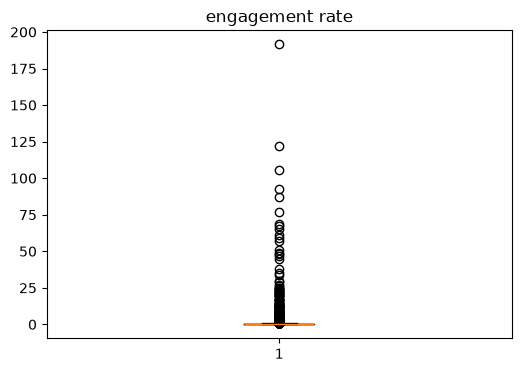

In [93]:
plt.figure(figsize=(6,4))
plt.boxplot(df['engagement_rate'])
plt.title('engagement rate')
plt.show()

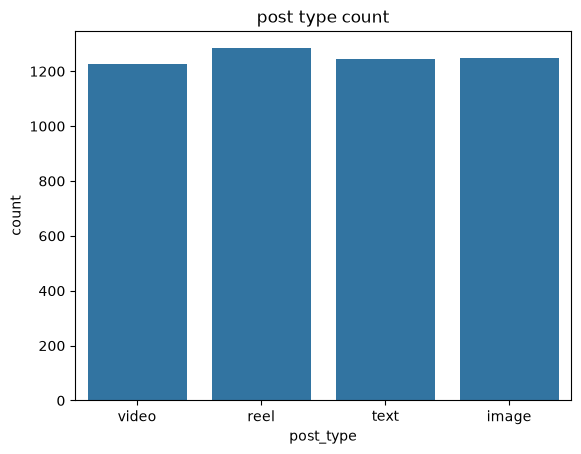

In [94]:
import seaborn as sns
sns.countplot(x='post_type',data=df)
plt.title('post type count')
plt.show()

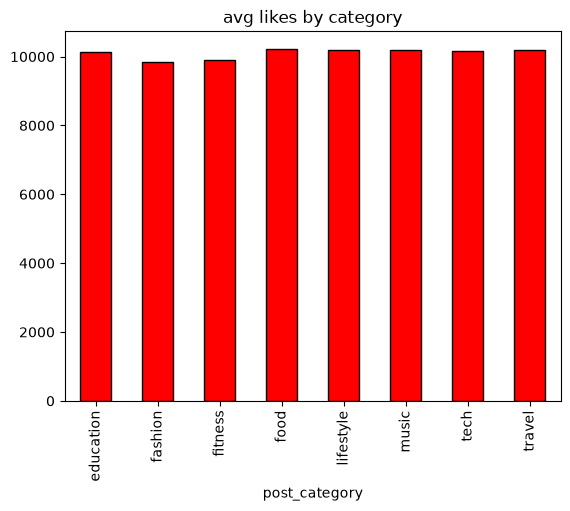

In [99]:
df.groupby('post_category')['likes'].mean().plot(kind='bar',color='red',edgecolor='black')
plt.title('avg likes by category')
plt.show()

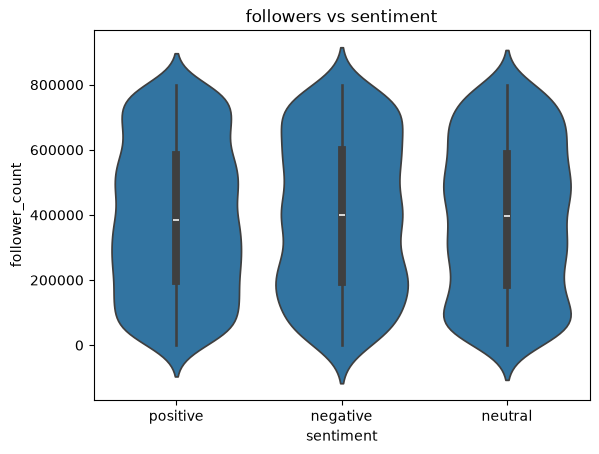

In [103]:
df['follower_count'] = pd.to_numeric(df['follower_count'], errors='coerce')
sns.violinplot(x='sentiment',y='follower_count',data=df)
plt.title('followers vs sentiment')
plt.show()

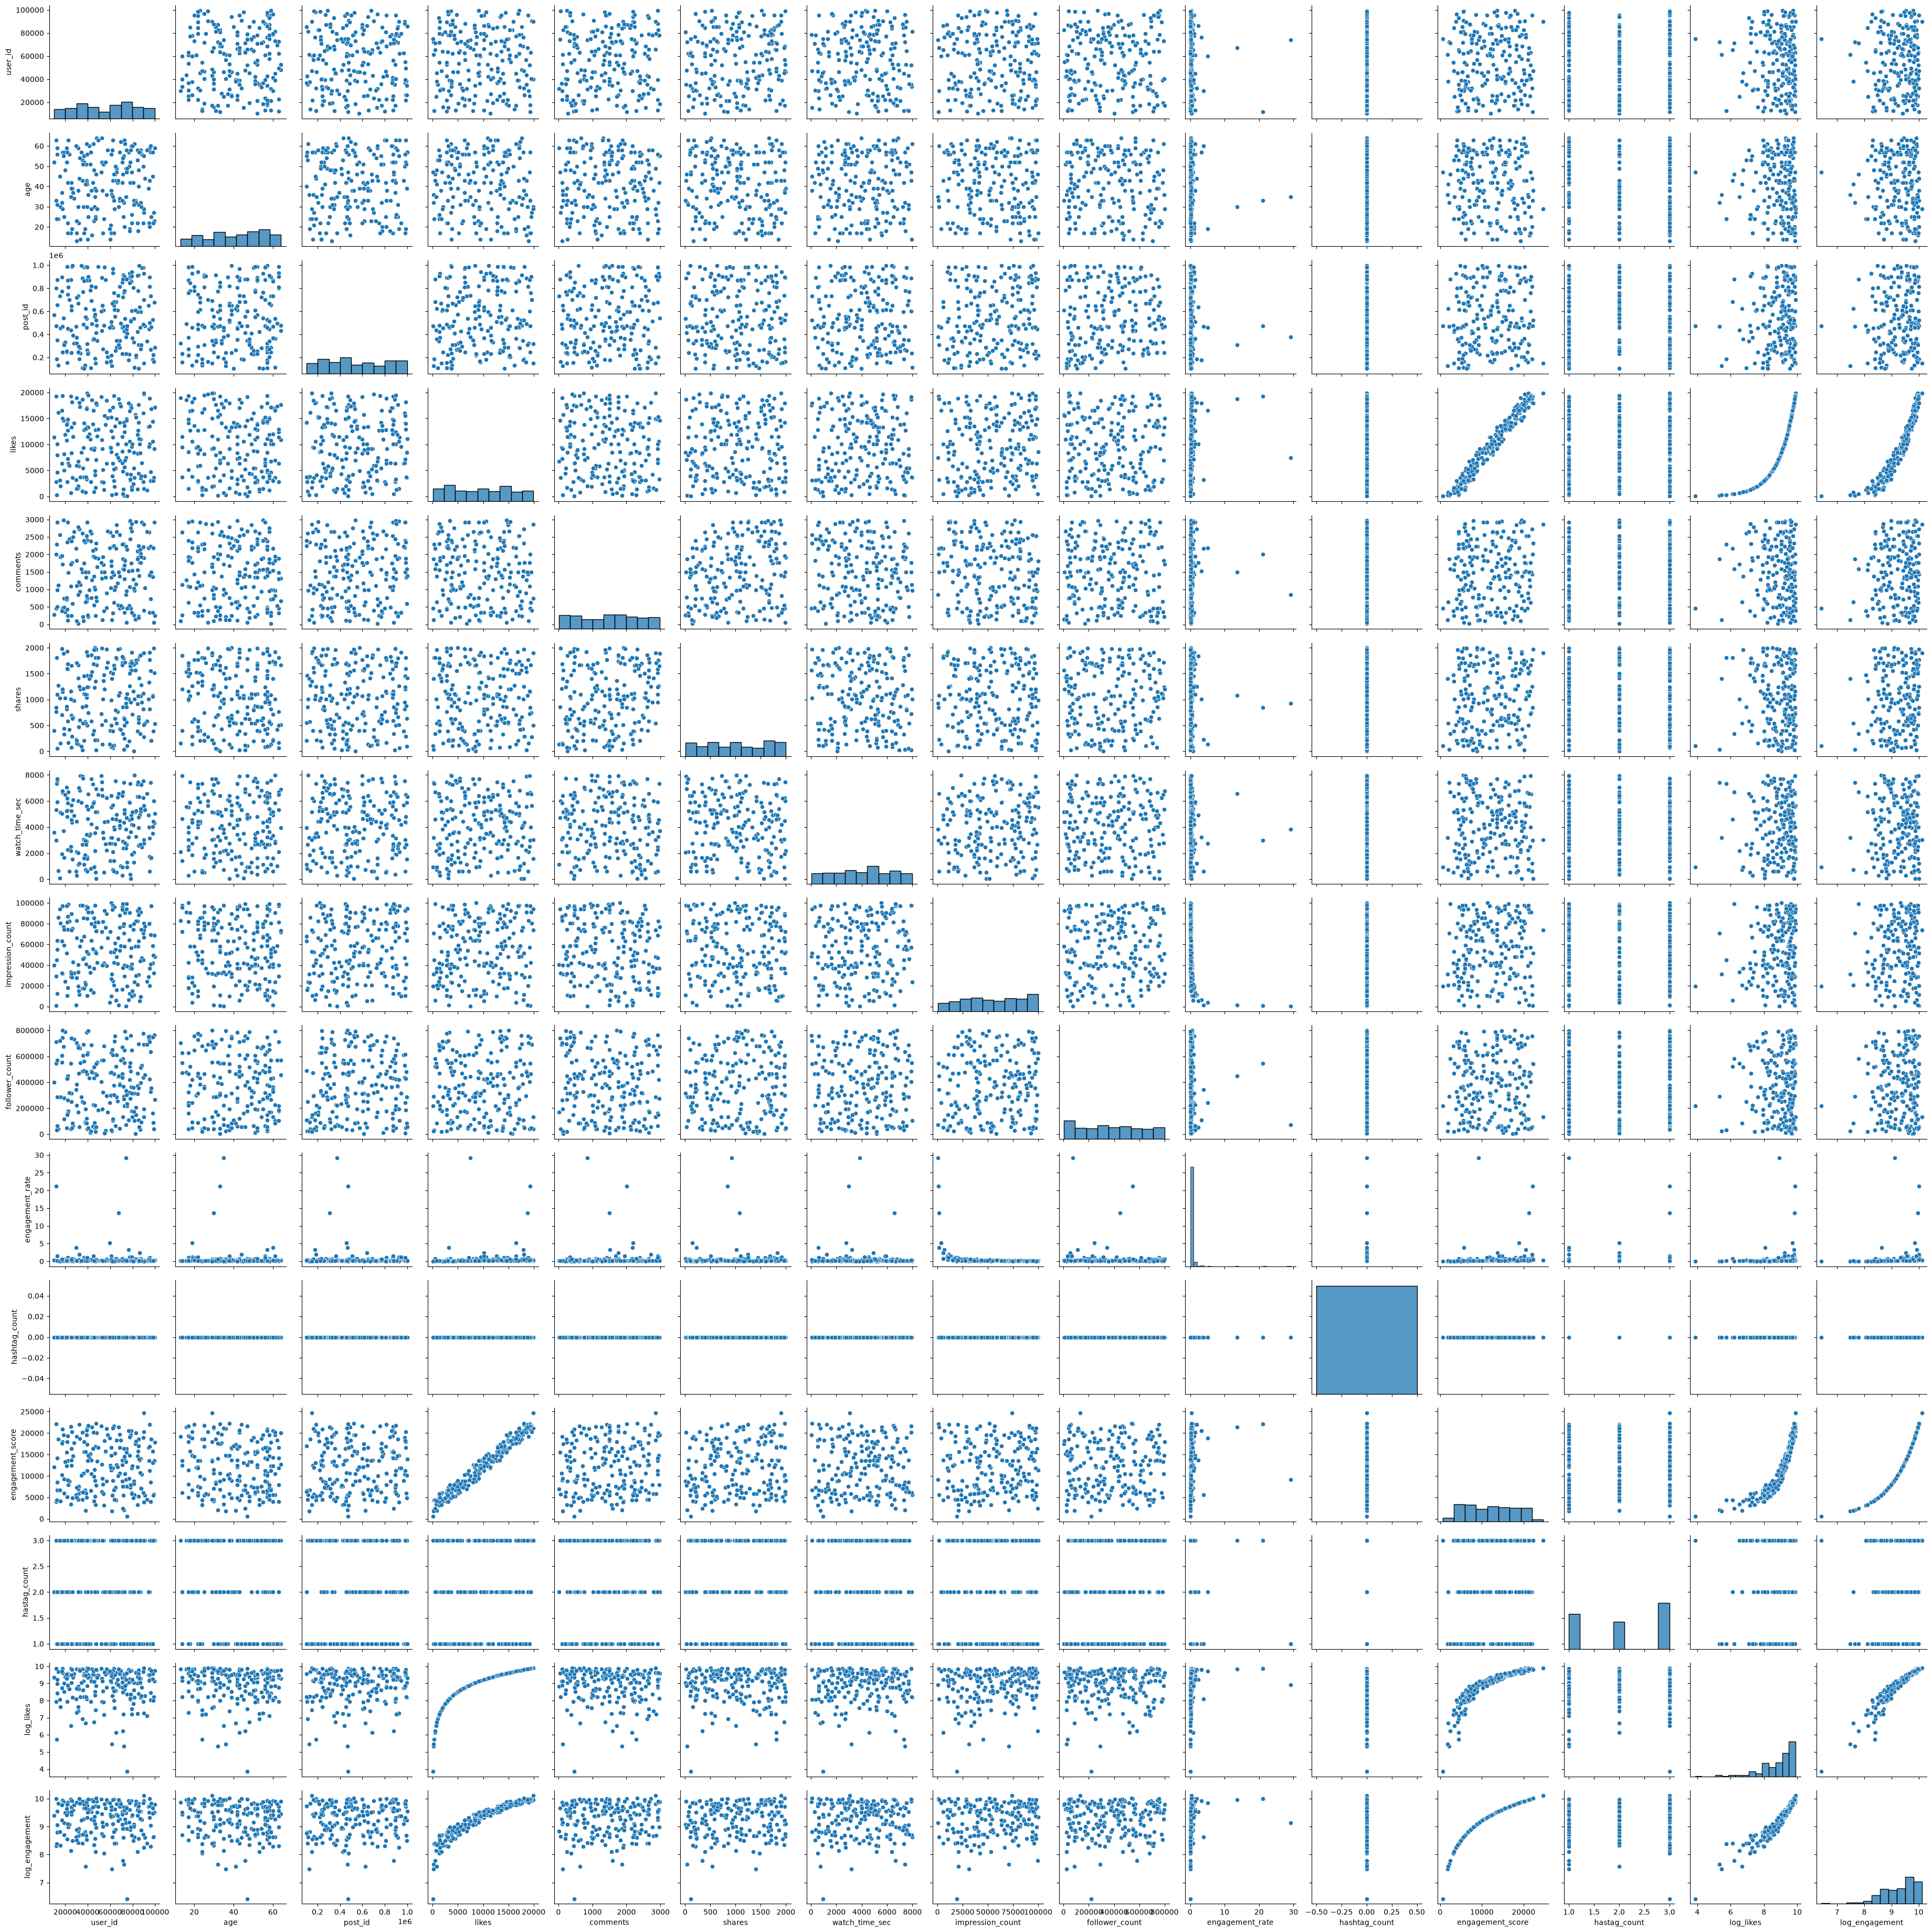

In [105]:
numeric_df = df.select_dtypes(include='number')
sns.pairplot(numeric_df.sample(200) if len(numeric_df) > 200 else numeric_df)
plt.show()

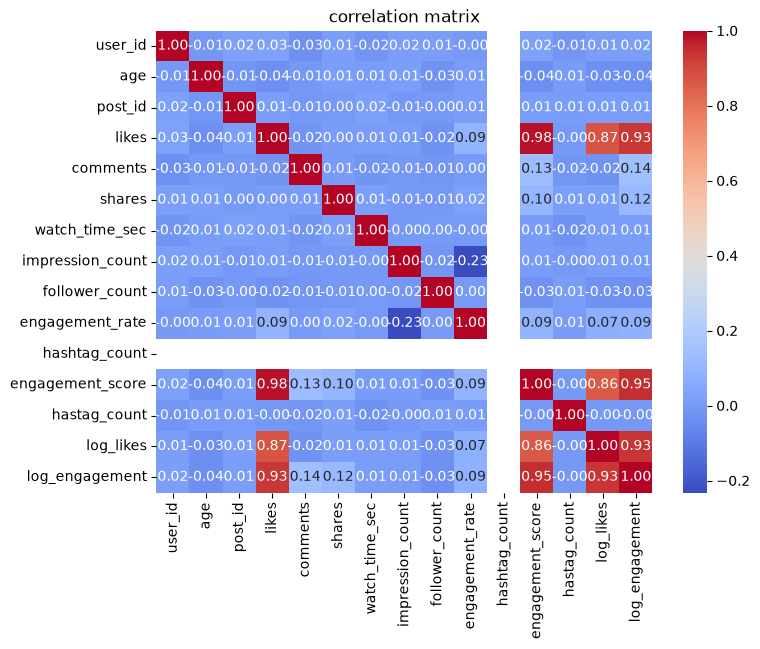

In [109]:
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap='coolwarm', fmt='.2f')
plt.title('correlation matrix')
plt.show()

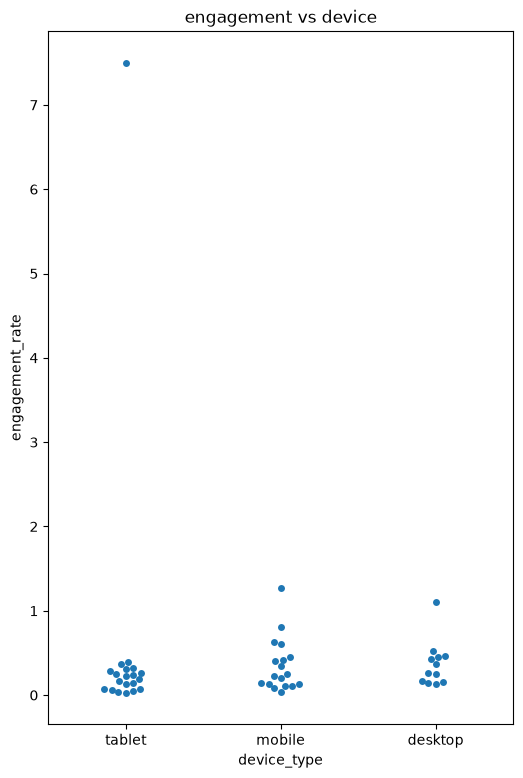

In [113]:
plt.figure(figsize=(6,9))
sns.swarmplot(x='device_type', y='engagement_rate', data=df.sample(50))
plt.title('engagement vs device')
plt.show()

In [116]:
!pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 540.0 kB/s eta 0:00:17
   --- ------------------------------------ 0.8/9.7 MB 680.4 kB/s eta 0:00:14
   ---- ----------------------------------- 1.0/9.7 MB 821.4 kB/s eta 0:00:11
   ----- ---------------------------------- 1.3/9.7 MB 926.5 kB/s eta 0:00:10
   ------ --------------------------------- 1.6/9.7 MB 1.0 MB/s eta 0:00:09
   ------- -------------------------------- 1.8/9.7 MB 1.0 MB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.7 MB 1.0 MB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.7 MB 953.5 kB/s eta 0:00:08
   ---------- -----------------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [119]:
import plotly.express as px
fig = px.scatter(df,x='watch_time_sec',y='engagement_rate',color='device_type',hover_data=['likes'],title='engagement vs watch time')
fig.show()

In [120]:
df.groupby ('post_type')['engagement_rate'].mean().sort_values(ascending=False)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

In [122]:
df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

In [124]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False).head(10)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [125]:
df.groupby('age')['engagement_rate'].mean().sort_values(ascending=False)

age
24.0    2.897327
55.0    2.599106
51.0    2.397295
48.0    1.675878
50.0    1.552627
41.0    1.540070
35.0    1.521596
47.0    1.402015
42.0    1.350772
63.0    1.303909
33.0    1.277557
30.0    1.270129
38.0    1.247501
16.0    1.226848
29.0    1.110432
25.0    1.041681
62.0    1.005127
14.0    1.003067
54.0    1.002622
49.0    0.999235
40.0    0.930504
23.0    0.922448
57.0    0.919751
18.0    0.888391
52.0    0.867426
17.0    0.858763
44.0    0.795102
27.0    0.775328
60.0    0.759586
15.0    0.714170
53.0    0.707924
19.0    0.676687
46.0    0.663994
36.0    0.609569
22.0    0.586786
32.0    0.581710
43.0    0.566439
34.0    0.557236
61.0    0.553854
56.0    0.524008
20.0    0.515541
45.0    0.513521
26.0    0.501467
59.0    0.495578
37.0    0.494109
13.0    0.455583
21.0    0.452752
31.0    0.440684
39.0    0.436184
58.0    0.435130
64.0    0.402533
28.0    0.385081
Name: engagement_rate, dtype: float64

In [126]:
df.groupby('is_verified')['engagement_rate'].mean()

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

In [128]:
df.groupby('watch_time_sec')['impression_count'].mean().sort_values(ascending=False).head(5)

watch_time_sec
217     99983.0
6971    99919.0
6107    99874.0
7441    99871.0
4275    99855.0
Name: impression_count, dtype: float64

In [129]:
df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

sentiment
negative    1.038486
neutral     0.991170
positive    0.954800
Name: engagement_rate, dtype: float64